# Adım 6.1: Makine Öğrenmesi - GBT Regressor

Bu notebook'ta, özellik mühendisliği tamamlanmış NYC Taxi verilerini kullanarak **Gradient Boosted Trees (GBT) Regressor** modelini eğiteceğiz. 

### Bu Adımda Yapılacaklar:
1. **Veri Yükleme:** feature(Gold) katmanından (Step 5) verilerin okunması.
2. **Özellik Hazırlığı:** Verilerin vektör formuna getirilmesi ve Train/Test ayrımı.
3. **MLflow Entegrasyonu:** Tüm parametre ve metriklerin loglanması.
4. **Model Değerlendirme:** RMSE, MAE, R² ve Residual analizi.
5. **Özellik Önemi:** Feature Importance analizi.

In [ ]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Spark Oturumunu Başlat (Delta ve Kafka desteği ile)
spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTraining-GBT") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

# MLflow Ayarları
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")

print("✅ Spark ve MLflow Hazır.")

✅ Spark ve MLflow Hazır.


## 1. Veri Okuma
Adım 5'te kaydettiğimiz Gold tablosunu yüklüyoruz.

In [2]:
gold_path = "/home/jovyan/work/data/delta/features"
df = spark.read.format("delta").load(gold_path)

print(f"Eğitim için yüklenen toplam kayıt sayısı: {df.count()}")
df.printSchema()

Eğitim için yüklenen toplam kayıt sayısı: 379995
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- kafka_timestamp: timestamp (nullable = true)
 |-- trip_duration_min: doub

## 2. Özelliklerin Vektörleştirilmesi
Spark ML algoritmaları, girdi özelliklerini tek bir `features` sütununda vektör olarak bekler.

In [3]:
# Modelde kullanılacak özellikler
feature_cols = [
    "trip_distance", 
    "trip_duration_min", 
    "average_speed", 
    "pickup_hour", 
    "day_of_week", 
    "is_airport_trip", 
    "is_rush_hour"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_df = assembler.transform(df).select("features", "total_amount")

# Veriyi %80 Eğitim, %20 Test olarak ayırıyoruz
train_df, test_df = final_df.randomSplit([0.8, 0.2], seed=42)

print(f"Eğitim seti: {train_df.count()} kayıt")
print(f"Test seti: {test_df.count()} kayıt")

Eğitim seti: 303979 kayıt
Test seti: 76016 kayıt


## 3. GBT Modeli Eğitimi ve MLflow Kaydı

In [4]:
with mlflow.start_run(run_name="GBT_Regressor_Final"):
    # 1. Model Parametreleri
    max_iter = 20
    max_depth = 5
    
    gbt = GBTRegressor(featuresCol="features", labelCol="total_amount", maxIter=max_iter, maxDepth=max_depth)
    
    # 2. Modeli Eğit
    print("🚀 GBT Modeli eğitiliyor, lütfen bekleyin...")
    model = gbt.fit(train_df)
    
    # 3. Tahmin Yap
    predictions = model.transform(test_df)
    
    # 4. Metrikleri Hesapla
    evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
    evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
    evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae = evaluator_mae.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)
    
    # 5. MLflow'a Logla
    mlflow.log_param("maxIter", max_iter)
    mlflow.log_param("maxDepth", max_depth)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)
    
    mlflow.spark.log_model(model, "gbt_model")
    
    print(f"✅ Model Başarıyla Eğitildi.")
    print(f"📊 RMSE: {rmse:.2f}")
    print(f"📊 MAE: {mae:.2f}")
    print(f"📊 R2 Score: {r2:.2f}")

🚀 GBT Modeli eğitiliyor, lütfen bekleyin...
✅ Model Başarıyla Eğitildi.
📊 RMSE: 6.57
📊 MAE: 2.81
📊 R2 Score: 0.90
🏃 View run GBT_Regressor_Final at: http://mlflow-server:5001/#/experiments/1/runs/ab26a4c037a5410e87c181bff12e44a2
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


## 4. Özellik Önemi (Feature Importance)
Hangi özelliğin tahmin üzerinde ne kadar etkili olduğunu görelim.

/tmp/ipykernel_217/4182244013.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


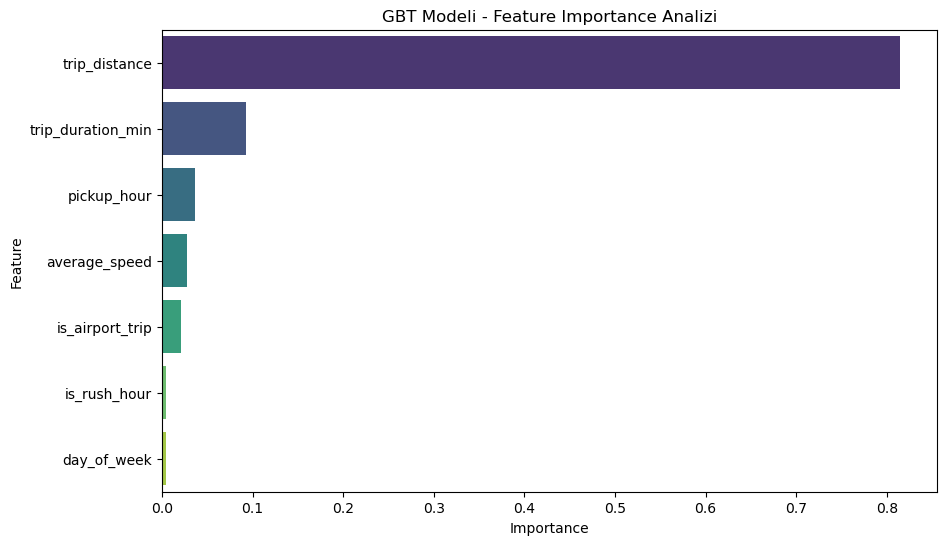

In [5]:
importance = model.featureImportances.toArray()
feat_imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importance})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('GBT Modeli - Feature Importance Analizi')
plt.show()

## 5. Gerçek vs Tahmin & Residual Analizi

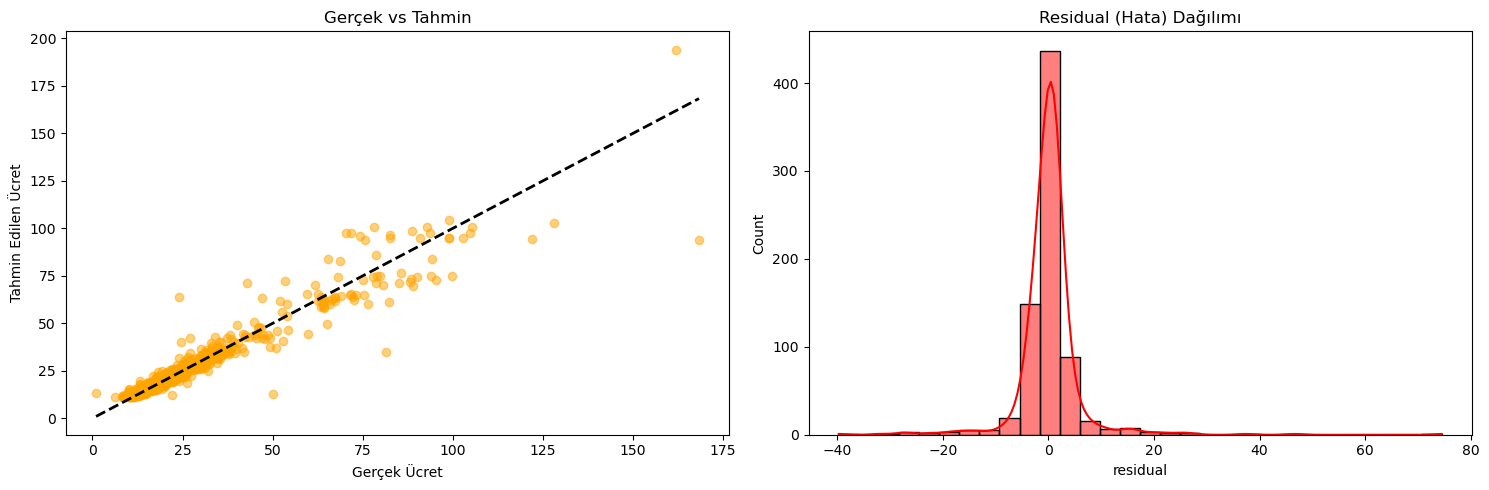

In [6]:
# Analiz için bir örneklem alalım
preds_pd = predictions.select("total_amount", "prediction").sample(0.01).toPandas()
preds_pd['residual'] = preds_pd['total_amount'] - preds_pd['prediction']

plt.figure(figsize=(15, 5))

# 1. Gerçek vs Tahmin Scatter Plot
plt.subplot(1, 2, 1)
plt.scatter(preds_pd['total_amount'], preds_pd['prediction'], alpha=0.5, color='orange')
plt.plot([preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 
         [preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 'k--', lw=2)
plt.xlabel('Gerçek Ücret')
plt.ylabel('Tahmin Edilen Ücret')
plt.title('Gerçek vs Tahmin')

# 2. Residual Dağılımı
plt.subplot(1, 2, 2)
sns.histplot(preds_pd['residual'], bins=30, kde=True, color='red')
plt.title('Residual (Hata) Dağılımı')

plt.tight_layout()
plt.show()

In [1]:
print("merhaba")

merhaba
